# Analiza EEG z MNE-Python: od surowego sygnału do klasyfikatora

Wykład praktyczny (ok. 90 min), 32 części. Jeden spójny eksperyment na rzeczywistych danych **PhysioNet EEG Motor Movement/Imagery** [1]–[3]: uczestnik 1, biegi 6, 10 i 14 (wyobrażanie ruchu obu rąk lub obu stóp). Zasada przewodnia: **kod → wynik → interpretacja**.

**Po wykładzie potrafisz:** wyjaśnić etapy analizy EEG, zinterpretować ERD/ERS w paśmie μ, ocenić klasyfikator CSP + LDA walidacją między przebiegami.

**Jak korzystać.** Komórki kodu wykonuj po kolei (wspólna przestrzeń nazw). Fragmenty kodu są identyczne z tymi na slajdach. Dane (ok. 8 MB) pobiera `eegbci.load_data()`. Wykresy rysuje moduł `python/plotting.py` (jeśli go nie ma obok notatnika, zachowane wyniki wykonania nadal są widoczne).

| Część | Zakres |
|---|---|
| I (1–10) | podstawy, dane, struktury MNE |
| II (11–19) | przetwarzanie wstępne, epoki, jakość, ICA |
| III (20–24) | analiza neurofizjologiczna: TFR, ERD/ERS, pasmo μ |
| IV (25–30) | uczenie maszynowe: CSP, LDA, walidacja |
| V (31–32) | reprodukowalność i zadanie |


In [ ]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
os.environ.setdefault("MNE_DATA", str(ROOT / "data"))
os.environ.setdefault("MNE_DATASETS_EEGBCI_PATH", os.environ["MNE_DATA"])
sys.path.insert(0, str(ROOT / "python"))
import warnings; warnings.filterwarnings("ignore")
try:   # rysunki z python/plotting.py (opcjonalne)
    import matplotlib.pyplot as plt
    import plotting
    from IPython.display import display
    plt.rcParams["figure.dpi"] = 170
    plotting._save = lambda fig, figdir, name: (display(fig), plt.close(fig))
    def show(key):
        plotting.HOOKS[key](globals(), None)
except ImportError:
    def show(key):
        print("(brak python/plotting.py: pominieto rysunek)")


## 1. Analiza EEG: cel i kontekst

EEG to wielokanałowy zapis napięcia z elektrod na skórze głowy. Pojedynczy kanał wygląda jak szum, a my chcemy odpowiedzieć na konkretne pytanie: **czy osoba wyobraża sobie ruch rąk, czy stóp?** Odpowiedź jest ukryta nie w kształcie fali, lecz w *mocy rytmów* nad korą ruchową. Do końca wykładu pokażemy, jak ją wydobyć i jak uczciwie sprawdzić, czy klasyfikator działa. Wykres przykładowego zapisu zobaczysz w części 9.

## 2. Pipeline analizy EEG

Kolejność operacji ma znaczenie. Każdy etap zależy od poprzedniego, a błąd na początku (np. wyciek informacji do zbioru testowego) unieważnia wynik końcowy.

```
Raw (7–12) → kontrola jakości (13, 18–19) → filtracja i referencja (14–15) → Epochs (16–18)
   → PSD / TFR / ERD (20–24) → CSP (25–26) → LDA (27) → walidacja między biegami (28–30)
```
Fazy I–II przygotowują dane, fazy III–IV to analiza i uczenie maszynowe. Walidacja jest ostatnim etapem, ale wymaga decyzji podjętych na początku (podział według biegów).

## 3. Zbiór EEGBCI

Dane pochodzą z systemu BCI2000 [1] i są publicznie dostępne w PhysioNet [2], [3]: 109 osób, 64 kanały, 160 Hz.

| bieg | zadanie | tryb |
|---|---|---|
| 5, 9, 13 | obie ręce / obie stopy | ruch wykonywany |
| **6, 10, 14** | obie ręce (T1) / obie stopy (T2) | **wyobrażanie** |

**Uwaga o etykietach:** kody T1 i T2 znaczą co innego w różnych biegach, więc zawsze mapujemy je według numeru biegu. W jednym biegu odpoczynek (T0) trwa 4,2 s, a zadanie 4,1 s, na przemian. Używamy jednej osoby i trzech biegów po ok. 125 s, więc wnioski nie uogólniają się na populację.

## 4. Instalacja środowiska

```bash
python -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
```
Wersje bibliotek mają znaczenie: nazwy montaży i część funkcji zmienia się między wydaniami MNE. Sprawdź swoje środowisko:

In [ ]:
import importlib.metadata as md
for p in ["mne", "numpy", "scipy", "matplotlib", "scikit-learn"]:
    print(p, md.version(p))


mne 1.13.2
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
scikit-learn 1.9.1


Zalecane: MNE 1.13.x (wykład przygotowano na 1.13.2).

## 5. Struktury danych MNE-Python

Każdy obiekt MNE opisuje inny zestaw osi. Przy każdej operacji zadawaj pytanie: *którą oś zmieniam lub usuwam?*

| obiekt | osie | powstaje z |
|---|---|---|
| `Raw` | kanały × czas | wczytania pliku |
| `Epochs` | próby × kanały × czas | `Raw` + zdarzenia |
| `Evoked` | kanały × czas | `epochs.average()` (znika oś prób) |
| `Spectrum` | kanały × częstotliwość | `compute_psd()` |
| `TFR` | kanały × częstotliwość × czas | `epochs.compute_tfr()` |

## 6. Import bibliotek

Kod inicjalizujący środowisko. `mne.set_log_level` ogranicza komunikaty, a wypisane wersje warto zapisywać przy każdej analizie, bo ułatwiają odtworzenie wyników.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from mne.io import (concatenate_raws,
                    read_raw_edf)

mne.set_log_level("WARNING")
print("MNE", mne.__version__)
print("NumPy", np.__version__)


MNE 1.13.2
NumPy 2.5.4


## 7. Pobieranie danych

`eegbci.load_data(uczestnik, biegi)` pobiera pliki EDF i zwraca listę ścieżek. Parametr `update_path=False` zapobiega interaktywnemu pytaniu o zmianę konfiguracji MNE (ważne w skryptach).

In [ ]:
files = eegbci.load_data(1, [6, 10, 14],
                         update_path=False)
for f in files:
    print(f.name, f.stat().st_size // 1000, "kB")


S001R06.edf 2596 kB
S001R10.edf 2596 kB
S001R14.edf 2596 kB


Wynik: trzy pliki po ok. 2,6 MB, po jednym na bieg.

## 8. Wczytywanie plików EDF

Wczytujemy każdy bieg osobno i łączymy funkcją `concatenate_raws`. **Pułapka:** funkcja modyfikuje pierwszy obiekt (`raws[0]`), dlatego długości biegów zapisujemy w `lens` *przed* połączeniem. Posłużą nam później jako grupy w walidacji. `standardize` usuwa kropki z nazw kanałów (`Fc5.` → `FC5`), co jest potrzebne do dopasowania montażu.

In [ ]:
raws = [read_raw_edf(f, preload=True)
        for f in files]
lens = [int(r.n_times) for r in raws]
raw = concatenate_raws(raws)
eegbci.standardize(raw)
print(lens, raw.n_times)
print(raw.ch_names[:5])


[20000, 20000, 20000] 60000
['FC5', 'FC3', 'FC1', 'FCz', 'FC2']


Trzy biegi po 20 000 próbek dają 60 000. Na granicach biegów MNE dodaje adnotacje `EDGE`/`BAD boundary`, dzięki którym filtracja i epokowanie omijają łączenia.

## 9. Metadane EEG

Podstawowe parametry odczytujemy z `raw.info`. Zwróć uwagę na **jednostki**: MNE przechowuje EEG w woltach.

In [ ]:
info = raw.info
fs = info["sfreq"]
print("sfreq:", fs, "| nchan:", info["nchan"])
print("czas:", raw.times[-1] + 1 / fs, "s")
cz = raw.get_data(picks="Cz")[0]
print("Cz [V]:", cz[:3])
print("Cz [uV]:", cz[:3] * 1e6)


sfreq: 160.0 | nchan: 64


czas: 375.0 s
Cz [V]: [8.2e-05 7.7e-05 6.5e-05]
Cz [uV]: [82. 77. 65.]


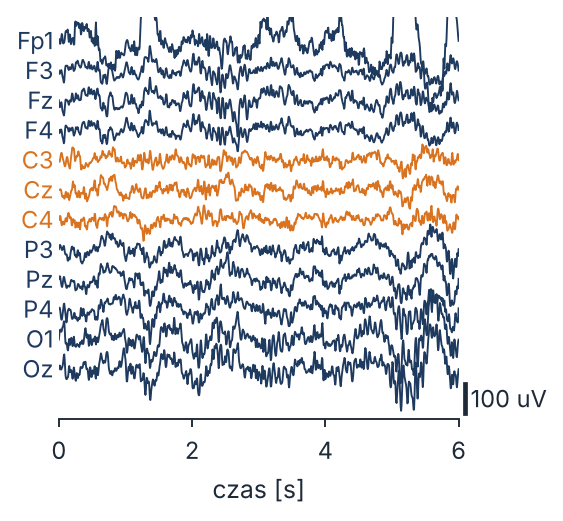

In [ ]:
show("s09")


160 Hz oznacza częstotliwość Nyquista 80 Hz. Wartość `8,2e-05 V` to 82 µV; typowy błąd to wykresy w woltach z nieopisaną osią. Powyżej widać przykładowy wielokanałowy zapis (1–40 Hz) z kanałami nad korą ruchową (C3, Cz, C4) wyróżnionymi kolorem.

*Pytanie:* ile próbek ma 125-sekundowy bieg przy 160 Hz? (20 000.)

## 10. Rozmieszczenie elektrod

`set_montage` przypisuje kanałom pozycje 3D, bez których nie narysujemy map topograficznych. Montaż `colin27_1005` to nowa nazwa dawnego `standard_1005` (przestarzałego w MNE 1.13; współrzędne są identyczne).

In [ ]:
raw.set_montage("colin27_1005")
pos = raw.get_montage().get_positions()
print(len(pos["ch_pos"]), "pozycji w montazu")
print("Cz [m]:", pos["ch_pos"]["Cz"].round(3))
print("C3 [m]:", pos["ch_pos"]["C3"].round(3))


64 pozycji w montazu
Cz [m]: [-0.001  0.028  0.14 ]
C3 [m]: [-0.067  0.023  0.105]


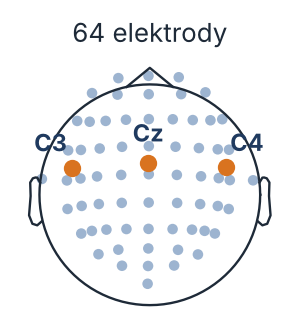

In [ ]:
show("s10")


Zaznaczone C3, Cz i C4 leżą nad korą ruchową i będą nas interesować. Ograniczenie: to montaż standardowy, nie zmierzone pozycje elektrod tej osoby.

## 11. Surowy sygnał EEG

Zawsze zaczynamy od inspekcji. Wycinamy 10 s i oglądamy pięć kanałów.

In [ ]:
seg = raw.copy().crop(20, 30)
chs = ["Fp1", "C3", "Cz", "C4", "Oz"]
data = seg.get_data(picks=chs, units="uV")
print(data.shape, np.ptp(data[1]).round(1))


(5, 1601) 419.0


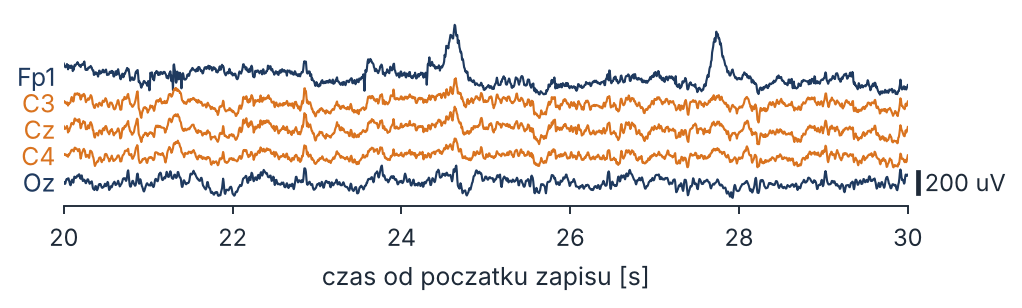

In [ ]:
show("s11")


Kanał czołowy Fp1 pokazuje wolne wychylenia, prawdopodobnie mrugnięcia. Rozstęp (peak-to-peak) C3 w tym oknie to 419 µV: sygnał jest zdominowany przez wolne zmiany i artefakty, a nie przez rytmy ruchowe. Surowego sygnału nie analizujemy bez kontroli.

## 12. Znaczniki eksperymentalne

Adnotacje to etykiety wstawione przez system stymulacji. Zliczamy je i oglądamy rozkład w czasie.

In [ ]:
ann = raw.annotations
desc = [d for d in ann.description
        if d[0] == "T"]
cnt = [desc.count(k) for k in ("T0","T1","T2")]
print("T0/T1/T2:", *cnt)


T0/T1/T2: 45 21 24


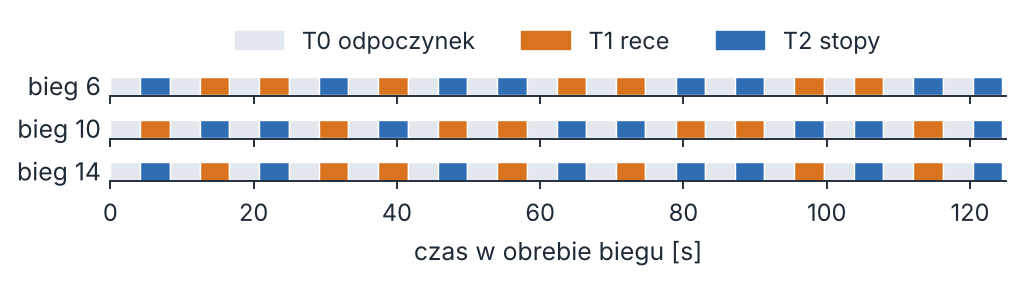

In [ ]:
show("s12")


W trzech biegach: 45 odpoczynków (T0), 21 zadań T1 (ręce) i 24 zadania T2 (stopy). Znacznik oznacza moment pojawienia się wskazówki, a **nie dowód**, że osoba wykonywała polecenie, więc mówimy o zadaniu, nie o stanie mózgu.

## 13. Widmo mocy EEG

Widmo Welcha [6] z oknem 4 s (`n_fft=640` przy 160 Hz) daje rozdzielczość 0,25 Hz. Skala logarytmiczna pokazuje, jak moc spada ze wzrostem częstotliwości.

In [ ]:
spec = raw.compute_psd(
    method="welch", fmax=45, n_fft=640)
psd = spec.get_data(picks="C3")[0]
mu = (spec.freqs >= 8) & (spec.freqs <= 13)
print("C3 mu:", (psd[mu] * 1e12).mean().round(1))


C3 mu: 43.5


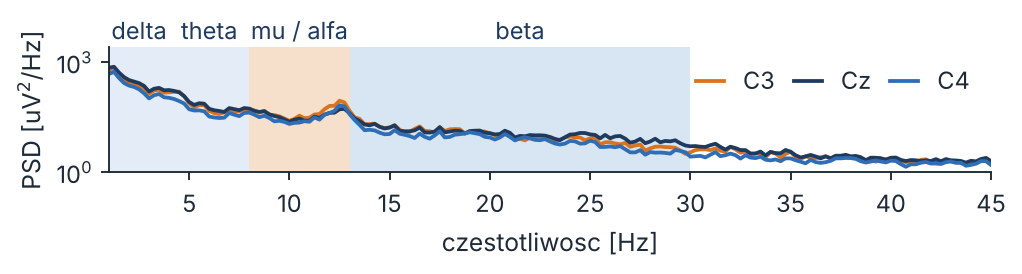

In [ ]:
show("s13")


Widoczny jest szczyt w okolicy 10–13 Hz (rytm alfa/μ); średnia moc C3 w paśmie 8–13 Hz to 43,5 µV²/Hz. Kolorowe pasma to konwencja, nie granice biologiczne. Zapis pochodzi z USA, więc ewentualna sieć to 60 Hz, powyżej zakresu wykresu.

## 14. Filtracja EEG

Tworzymy dwie kopie: **1–40 Hz** (ICA, kontrola jakości, analiza czasowo-częstotliwościowa) i **7–30 Hz** (klasyfikacja). Filtr FIR (`firwin`) działa osobno na segmentach rozdzielonych adnotacjami `EDGE`, więc na łączeniach biegów nie powstają artefakty. Dobór filtrów wpływa na kształt sygnału [7].

In [ ]:
raw_tfr = raw.copy().filter(
    1.0, 40.0, fir_design="firwin")
raw_clf = raw.copy().filter(
    7.0, 30.0, fir_design="firwin")
print(raw_clf.info["lowpass"], "Hz")


30.0 Hz


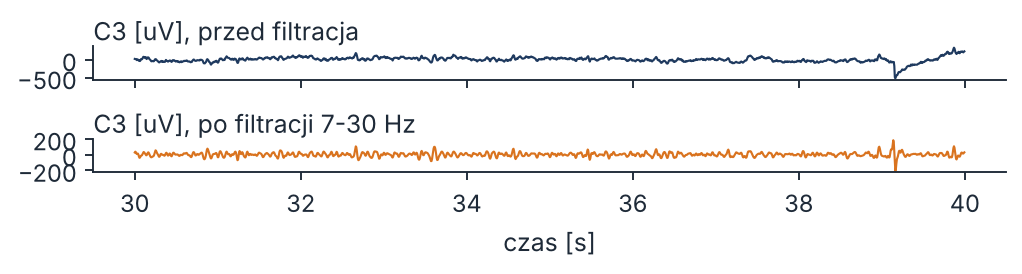

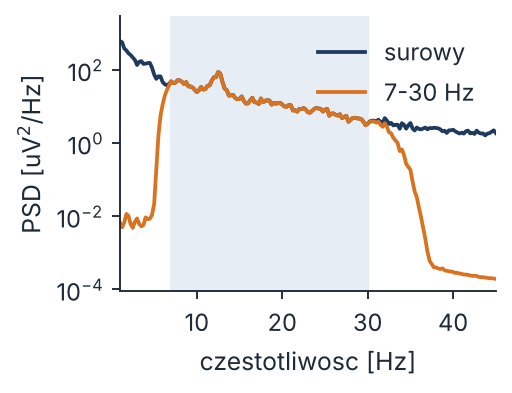

In [ ]:
show("s14")


Po filtracji znika dryf, ale duży artefakt w 39. sekundzie pozostaje: **filtracja usuwa pasma, nie artefakty.** Prawy wykres pokazuje widmo przed i po filtracji.

## 15. Referencjonowanie EEG

Potencjał jest zawsze różnicą względem referencji. Stosujemy średnią referencję (*average reference*), po której suma po kanałach jest równa zero.

In [ ]:
for r in (raw_tfr, raw_clf):
    r.set_eeg_reference("average",
                        projection=False)
x = raw_clf.get_data()
print("suma = 0:", abs(x.sum(0)).max() < 1e-12)


suma = 0: True


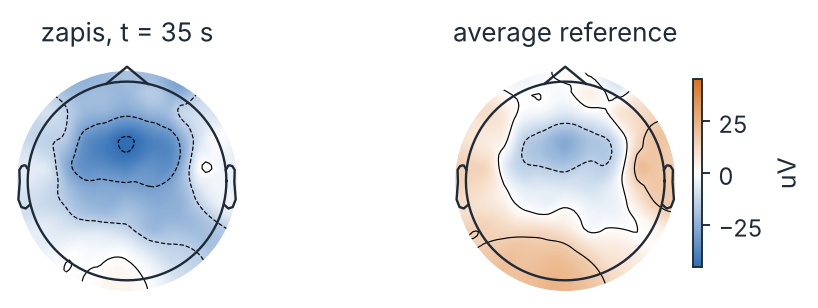

In [ ]:
show("s15")


Mapa po lewej to rozkład potencjału w jednej chwili przy referencji z zapisu, po prawej przy średniej. Zmienia się topografia i amplitudy, więc **nie porównuj map z różnymi referencjami.** Konsekwencja techniczna: macierz kowariancji ma rząd 63 (nie 64), więc w CSP stosujemy regularyzację.

*Pytanie:* dlaczego rząd spada o jeden?

## 16. Wykrywanie zdarzeń

`events_from_annotations` zamienia adnotacje na macierz zdarzeń: numer próbki, wartość poprzedzająca, kod. Mapujemy jawnie T1 → 1 i T2 → 2, pomijając T0.

In [ ]:
events, _ = mne.events_from_annotations(
    raw_tfr, event_id={"T1": 1, "T2": 2})
print(events.shape)
print(events[:4])
print(np.bincount(events[:, 2])[1:])


(45, 3)
[[ 672    0    2]
 [2000    0    1]
 [3328    0    1]
 [4656    0    2]]
[21 24]


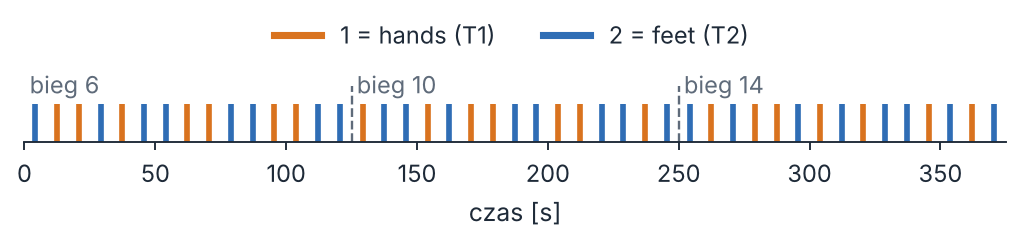

In [ ]:
show("s16")


Mamy 45 zdarzeń (21 × ręce, 24 × stopy). Pierwsze przypada na próbkę 672, czyli 4,2 s po starcie. Przerywane linie to granice biegów.

## 17. Segmentacja EEG

Epoki obejmują okno od −1,5 do 4,5 s względem wskazówki. Margines jest szerszy niż w minimalnym wariancie, aby falki Morleta nie miały efektów brzegowych w oknie odniesienia. Bez korekcji *baseline* (zrobimy ją później dla mocy).

In [ ]:
epochs = mne.Epochs(
    raw_tfr, events, dict(hands=1, feet=2),
    tmin=-1.5, tmax=4.5, baseline=None,
    reject=None, preload=True)
print(epochs.get_data().shape)


(45, 64, 961)


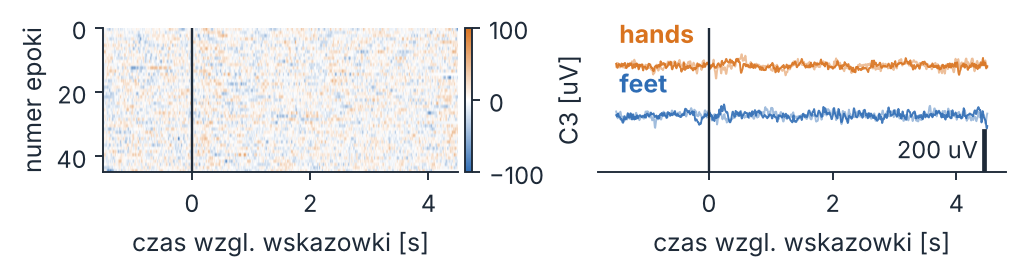

In [ ]:
show("s17")


Tablica ma wymiary (45 prób, 64 kanały, 961 próbek). Pojedyncze epoki wyglądają jak szum: rytm ujawni dopiero analiza mocy.

## 18. Kontrola jakości

Automatyczne kryteria trzeba kalibrować na danych. Próg 200 µV (częsty przykład z podręczników) sprawdzamy na naszych epokach, a następnie porównujemy z progiem odpornym: mediana + 3 skalowane odchylenia MAD, **bez użycia etykiet klas**.

In [ ]:
import scipy.stats as st
pp = np.ptp(epochs.get_data(), axis=2).max(1)
mad = st.median_abs_deviation(pp, scale="normal")
thr = np.median(pp) + 3 * mad
print("200 uV:", (pp > 200e-6).sum(), "z", len(pp))
epochs.drop_bad(reject=dict(eeg=thr))
print(round(thr * 1e6), "uV;", len(epochs), "epok")


200 uV: 43 z 45
722 uV; 44 epok


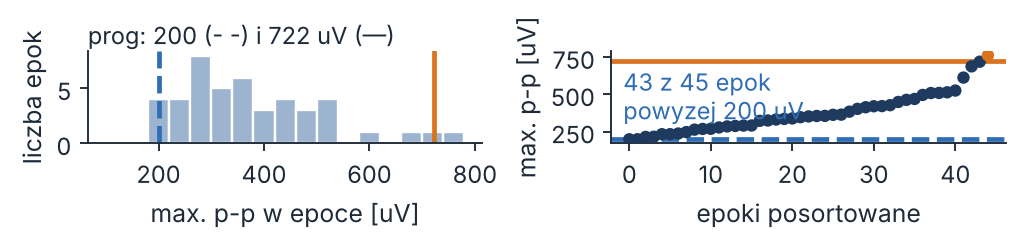

In [ ]:
show("s18")


Próg 200 µV odrzuciłby 43 z 45 epok (bezużyteczny przy 1–40 Hz). Próg odporny wynosi 722 µV i odrzuca jedną epokę. Wniosek: raportuj próg i jego skutek. Ograniczenie: próg liczymy na całym zbiorze, ale nie używa on etykiet, więc nie powoduje wycieku.

## 19. Independent Component Analysis

ICA [8] rozkłada sygnał na statystycznie niezależne źródła. Dopasowujemy 20 składowych i szukamy kandydatów na artefakt oczny, korelując składowe z kanałem Fp1 (zastępczy EOG, bo nie mamy kanału EOG).

In [ ]:
ica = mne.preprocessing.ICA(n_components=20,
                            random_state=97)
ica.fit(raw_tfr)
idx, sc = ica.find_bads_eog(raw_tfr, ch_name="Fp1")
print("kandydaci:", list(map(int, idx)))


kandydaci: [0]


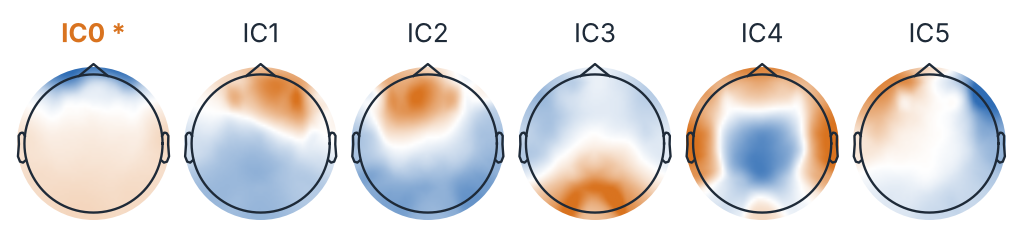

In [ ]:
show("s19")


Kandydatem jest składowa IC0 o czołowej topografii. **To identyfikacja, nie decyzja:** nie usuwamy jej (`ica.exclude` pozostaje puste), bo brak potwierdzenia przebiegu. Nietypowa topografia nie musi oznaczać artefaktu.

## 20. Uśrednianie EEG

Średnia po próbach (`epochs.average()`) daje `Evoked`. Rytmy ruchowe nie mają stałej fazy względem wskazówki, więc przy uśrednianiu się znoszą [9].

In [ ]:
evokeds = {c: epochs[c].average()
           for c in ["hands", "feet"]}
print([e.nave for e in evokeds.values()])


[21, 23]


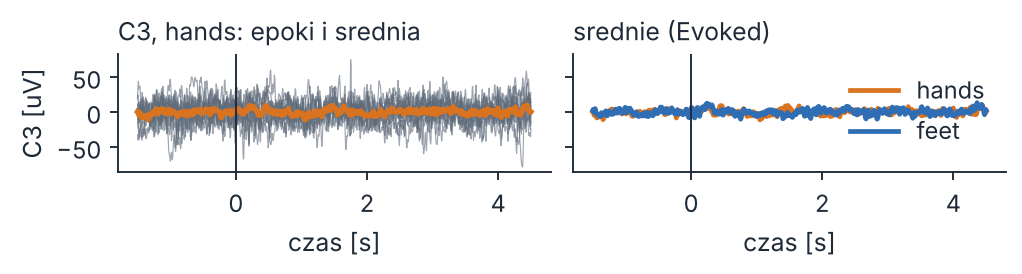

In [ ]:
show("s20")


Lewy wykres: pojedyncze epoki C3 (szare) i ich średnia, bliska zeru. Prawy: średnie dla obu klas praktycznie się nie różnią. Do wyobrażania ruchu potrzebna jest analiza **mocy** w pasmach, czyli analiza czasowo-częstotliwościowa.

## 21. Analiza czasowo-częstotliwościowa

Transformacja falkowa Morleta [10] z liczbą cykli równą połowie częstotliwości daje kompromis między rozdzielczością czasu i częstotliwości. Obliczamy moc dla każdej klasy.

In [ ]:
freqs = np.arange(6, 36, 1.0)
tfr = {c: epochs[c].compute_tfr(
           "morlet", freqs, n_cycles=freqs / 2,
           decim=2, average=True)
       for c in ["hands", "feet"]}
print(tfr["hands"].data.shape)


(64, 30, 481)


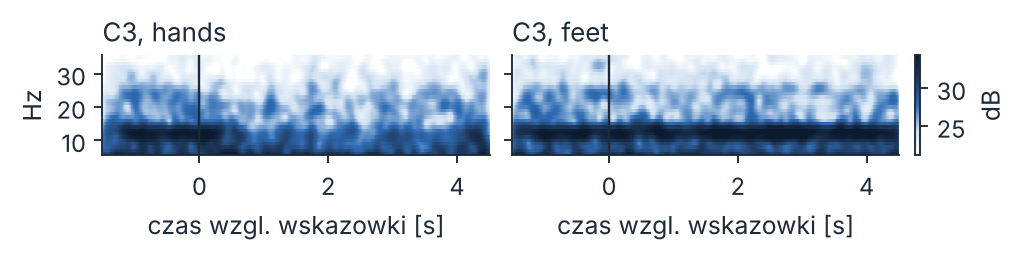

In [ ]:
show("s21")


Wynik ma kształt (64 kanały, 30 częstotliwości, 481 punktów czasu). Na C3 dla rąk po wskazówce wyraźnie słabnie pas ok. 12 Hz, dla stóp pozostaje silny. To jeszcze nie ERD: brakuje odniesienia do okresu bazowego.

## 22. Normalizacja i ERD/ERS

Moc normalizujemy procentowo względem okresu od −0,8 do −0,2 s. Wartość ujemna to **desynchronizacja związana ze zdarzeniem (ERD)**, dodatnia to **synchronizacja (ERS)** [9]. Okno bazowe omija 0,2 s tuż przed wskazówką, aby uniknąć przeciekania falek.

In [ ]:
erd = {c: t.copy().apply_baseline(
           (-0.8, -0.2), mode="percent")
       for c, t in tfr.items()}
win = dict(fmin=8, fmax=13, tmin=1, tmax=3)
v = erd["hands"].get_data(picks=["C3"], **win)
print("C3, hands: %.0f %%" % (100 * v.mean()))


C3, hands: -55 %


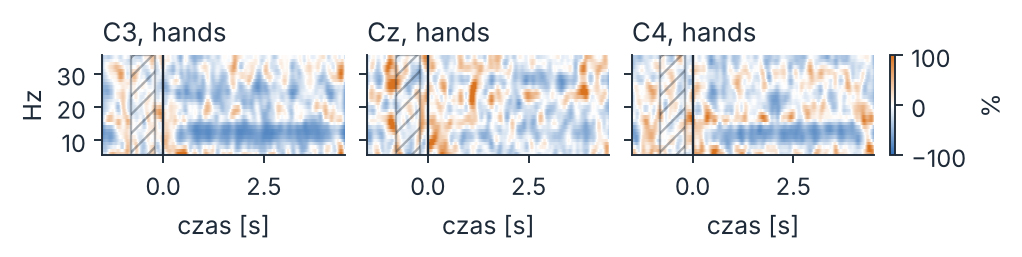

In [ ]:
show("s22")


Dla rąk na C3 średnia zmiana mocy 8–13 Hz w oknie 1–3 s wynosi **−55%**. Wracamy do pytania z początku: zadanie rozpoznajemy po spadku mocy rytmu μ nad korą ruchową. Ograniczenie: jeden uczestnik.

## 23. Porównanie warunków eksperymentalnych

Porównujemy przebieg czasowy mocy 8–13 Hz dla rąk i stóp na C3, Cz i C4 (zacieniowane okno 1–3 s).

In [ ]:
for ch in ["C3", "Cz", "C4"]:
    h, f = [100 * erd[c].get_data(
            picks=[ch], **win).mean()
            for c in ("hands", "feet")]
    print(ch, round(h), round(f))


C3 -55 12
Cz -18 19
C4 -45 18


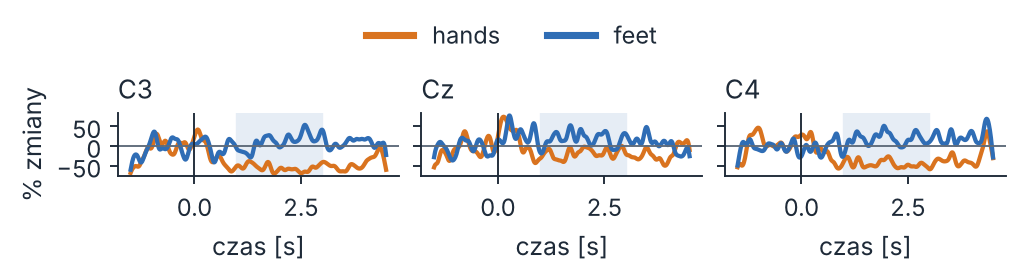

In [ ]:
show("s23")


Dla rąk spadek wynosi −55% (C3), −18% (Cz) i −45% (C4). Dla stóp moc w tych kanałach rośnie o 12–19%. Różny kierunek zmian to właśnie cecha, którą wykorzysta klasyfikator. To obserwacja dla jednej osoby, nie dowód ogólnego mechanizmu; oczekiwanego ogniskowego ERD na Cz dla stóp tu nie widać.

## 24. Analiza pasma μ

Mapy topograficzne średniej zmiany mocy 8–13 Hz w oknie 1–3 s dla rąk, stóp i ich różnicy.

In [ ]:
mu = {c: 100 * erd[c].get_data(
          **win).mean((1, 2))
      for c in ["hands", "feet"]}
for c, v in mu.items():
    print(c, round(v.min()), round(v.max()))


hands -55 42
feet -16 74


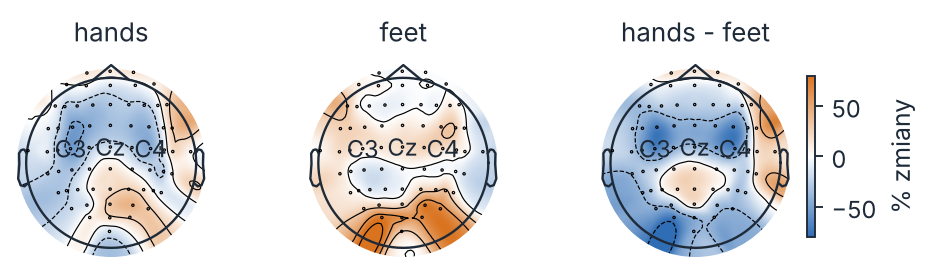

In [ ]:
show("s24")


Zakresy: ręce od −55% do +42%, stopy od −16% do +74%. Silny wzrost nad okolicą potyliczną dla stóp może mieć inne wyjaśnienie niż ruch (np. rytm alfa związany z widzeniem). **Zmiana mocy na elektrodzie nie wskazuje jednoznacznie źródła neuronalnego**: przewodnictwo objętościowe rozmywa rozkład.

## 25. Common Spatial Patterns

CSP [11], [12] szuka filtrów przestrzennych $w$, które maksymalizują stosunek wariancji jednej klasy do sumy wariancji obu klas:

$$\max_{w}\ \frac{w^{\top}\Sigma_1 w}{w^{\top}(\Sigma_1+\Sigma_2)\,w}\quad\Longleftrightarrow\quad \Sigma_1 w=\lambda\,(\Sigma_1+\Sigma_2)\,w$$

To uogólniony problem własny. Wartości własne bliskie 1 i 0 odpowiadają filtrom, które najlepiej wyróżniają klasy. **Cechą próby** jest logarytm wariancji sygnału po przefiltrowaniu przestrzennym:

$$f_k=\log\operatorname{var}\!\left(w_k^{\top}x\right)$$

Intuicja: dla dwóch kanałów klasy tworzą różnie zorientowane elipsy rozkładu; filtr $w$ wskazuje kierunek o największym stosunku wariancji. CSP uczy się **z etykiet**, więc wymaga ostrożnej walidacji (części 27–28).

## 26. Przygotowanie danych ML

Budujemy macierz `X` (próby × kanały × czas), wektor etykiet `y` i identyfikatory grup `groups` (numer biegu). Klasyfikujemy okno 0,5–3,5 s, **wybrane a priori**, nie dobrane na danych. Epoki pochodzą z danych 7–30 Hz i tych samych zdarzeń, które przeszły kontrolę jakości.

In [ ]:
epochs_clf = mne.Epochs(
    raw_clf, epochs.events,
    dict(hands=1, feet=2),
    tmin=-1.5, tmax=4.5, baseline=None,
    reject_by_annotation=False, preload=True)
X = epochs_clf.get_data(tmin=0.5, tmax=3.5)
y = epochs_clf.events[:, 2]
t0 = epochs_clf.events[:, 0] - raw.first_samp
edges = np.cumsum(lens)
groups = np.searchsorted(edges, t0, side="right")
print(X.shape, np.bincount(y)[1:],
      np.bincount(groups))


(44, 64, 480) [21 23] [15 14 15]


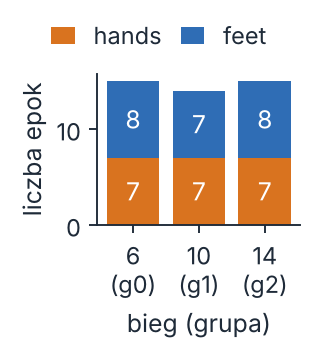

In [ ]:
show("s26")


`X` ma kształt (44, 64, 480); klasy: 21 × ręce, 23 × stopy; grupy (biegi) mają 15, 14 i 15 epok. Klasy są w każdej grupie zrównoważone.

## 27. Klasyfikator CSP + LDA

Pipeline scikit-learn [5] łączy CSP i LDA, dzięki czemu przy walidacji krzyżowej CSP jest dopasowywane **tylko na zbiorze treningowym** każdego foldu. To eliminuje przeciek informacji. Używamy czterech składowych i regularyzacji Ledoit–Wolf [13], bo po średniej referencji kowariancja jest osobliwa.

In [ ]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis as LDA)
from sklearn.pipeline import make_pipeline

clf = make_pipeline(
    CSP(n_components=4, reg="ledoit_wolf",
        log=True),
    LDA())
print([name for name, _ in clf.steps])


['csp', 'lineardiscriminantanalysis']


*Pytanie:* co by się stało, gdybyśmy dopasowali CSP na całym zbiorze przed walidacją? (Filtry „znałyby” zbiór testowy, a wynik byłby zawyżony.)

## 28. Walidacja modelu

`GroupKFold` dzieli epoki według biegów: trening na dwóch biegach, test na trzecim. Epoki z jednej sesji są skorelowane, więc losowy podział może zawyżać wyniki [14]. Dla porównania liczymy też losowy `StratifiedKFold`.

In [ ]:
import sklearn.model_selection as ms
cv = ms.GroupKFold(n_splits=3)
bal = dict(scoring="balanced_accuracy")
scores = ms.cross_val_score(
    clf, X, y, groups=groups, cv=cv, **bal)
skf = ms.StratifiedKFold(
    3, shuffle=True, random_state=0)
rnd = ms.cross_val_score(
    clf, X, y, cv=skf, **bal)
print("biegi :", scores.round(2))
print("losowo:", rnd.round(2))


biegi : [0.93 1.   1.  ]
losowo: [0.88 0.93 1.  ]


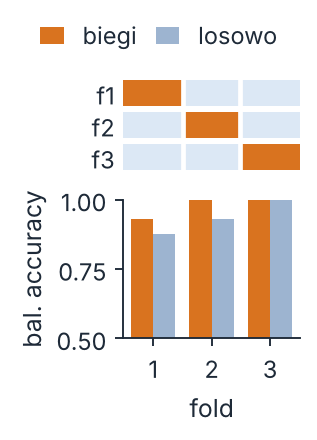

In [ ]:
show("s28")


Po biegach: 0,93 / 1,0 / 1,0. Losowy podział: 0,88 / 0,93 / 1,0. W tym zbiorze losowy podział **nie** zawyżył wyniku, a różnice mieszczą się w szumie przy 44 próbach. Zalecenie pozostaje: dziel według biegów. Nie oceniamy tu generalizacji na nowe osoby.

## 29. Ocena jakości klasyfikacji

Zbalansowana dokładność (*balanced accuracy*), macierz pomyłek i porównanie z klasyfikatorem większościowym.

In [ ]:
import sklearn.metrics as sm
from sklearn.dummy import DummyClassifier
bas = sm.balanced_accuracy_score
y_hat = ms.cross_val_predict(
    clf, X, y, groups=groups, cv=cv)
ba = bas(y, y_hat)
cm = sm.confusion_matrix(y, y_hat)
dummy = DummyClassifier(
    strategy="most_frequent")
y_base = ms.cross_val_predict(
    dummy, X, y, groups=groups, cv=cv)
print(round(ba, 3), round(bas(y, y_base), 3))


0.976 0.5


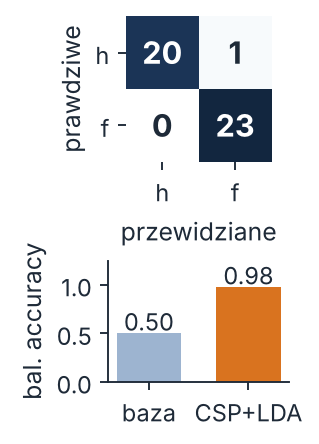

In [ ]:
show("s29")


Balanced accuracy = **0,976**, klasyfikator bazowy = 0,5. Macierz pomyłek: 20 rąk i 23 stóp rozpoznanych poprawnie, jedna ręka uznana za stopę. Wynik dotyczy jednej osoby i 44 prób, więc niepewność jest duża [14]. To nie dowód na ogólną skuteczność.

## 30. Interpretacja komponentów CSP

Model dopasowany na całym zbiorze służy **wyłącznie do interpretacji**, nie do oceny. Rozróżnij: **filtry** (jak kombinować kanały, by wyróżnić klasę) i **wzorce** (jak źródło rzutuje na elektrody) [15]. Interpretujemy wzorce.

In [ ]:
csp = CSP(n_components=4, reg="ledoit_wolf",
          log=True)
csp.fit(X, y)
print(csp.patterns_.shape, csp.filters_.shape)


(63, 64) (63, 64)


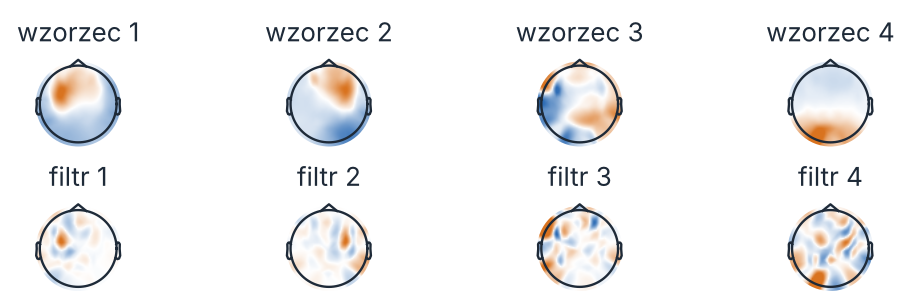

In [ ]:
show("s30")


Wzorce (górny rząd) mają czytelną topografię, filtry (dolny) wyglądają na bardziej „poszarpane”: dobrze wyróżniają klasy, ale nie mówią wprost, skąd pochodzi sygnał. Liczba składowych (63) wynika ze średniej referencji. Interpretacja ma charakter korelacyjny, nie przyczynowy.

## 31. Eksport wyników

Minimum reprodukowalności [16]: dane przetworzone, parametry, wynik i środowisko.

In [ ]:
import json, sklearn
from pathlib import Path
out = Path("output/results")
out.mkdir(parents=True, exist_ok=True)
epochs_clf.save(out / "S001-clf-epo.fif",
                overwrite=True)
res = dict(subject=1, n_epochs=len(y),
           bal_acc=round(ba, 3),
           mne=mne.__version__,
           sklearn=sklearn.__version__)
f = out / "results.json"
f.write_text(json.dumps(res))
print(sorted(p.name for p in out.iterdir()))


['S001-clf-epo.fif', 'results.json']


Zapisano epoki w formacie FIF i wyniki z wersjami oprogramowania w JSON (katalog `output/results`). Surowych danych nie zapisujemy: pobiera je `load_data`.

## 32. Podsumowanie i zadanie praktyczne

Funkcja `run_subject` z `python/analysis.py` wykonuje cały tor dla wybranej osoby.

In [ ]:
import sys
sys.path.insert(0, "python")
from analysis import run_subject

res = run_subject(subject=1)
print(res["n_epochs"], round(res["bal_acc"], 3))
# zadanie: subject=2


44 0.976


Wynik (44 epoki, 0,976) jest zgodny z przebiegiem wykładu.

**Zadania:**
1. Uruchom `run_subject(subject=2)` (walidacja w obrębie osoby).
2. Wytrenuj model na osobie 1 i przetestuj na osobie 2.
3. Porównaj wyniki 1 i 2. Parametry (okno, pasma) wybieraj **bez użycia zbioru testowego**.

**Ograniczenia:** jedna osoba, 44 epoki, parametry ustalone a priori; wyniki są eksploracyjne.

## Dodatek: test permutacyjny (ok. 1,5 min)

Czy wynik 0,976 mógłby wynikać z przypadku? Permutujemy etykiety 200 razy i porównujemy.

In [ ]:
y_hat = ms.cross_val_predict(
    clf, X, y, groups=groups, cv=cv)
s, perm, p = ms.permutation_test_score(
    clf, X, y, groups=groups, cv=cv, random_state=0,
    scoring="balanced_accuracy", n_permutations=200)
print("p =", round(p, 3), "| srednia perm.:", perm.mean().round(2))


p = 0.005 | srednia perm.: 0.49


Wynik: p = 0,005, średnia permutacji 0,49 (poziom przypadku). Test potwierdza, że klasyfikator działa lepiej niż losowo, ale nie usuwa ograniczeń wynikających z jednej osoby.

## Bibliografia

[1] G. Schalk et al., „BCI2000: A general-purpose brain-computer interface (BCI) system,” *IEEE Trans. Biomed. Eng.*, vol. 51, no. 6, pp. 1034–1043, 2004, doi:10.1109/TBME.2004.827072.
[2] A. L. Goldberger et al., „PhysioBank, PhysioToolkit, and PhysioNet,” *Circulation*, vol. 101, no. 23, pp. e215–e220, 2000, doi:10.1161/01.CIR.101.23.e215.
[3] G. Schalk, „EEG Motor Movement/Imagery Dataset (v1.0.0),” PhysioNet, 2009, doi:10.13026/C28G6P.
[4] A. Gramfort et al., „MEG and EEG data analysis with MNE-Python,” *Front. Neurosci.*, vol. 7, p. 267, 2013, doi:10.3389/fnins.2013.00267.
[5] F. Pedregosa et al., „Scikit-learn: Machine learning in Python,” *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.
[6] P. D. Welch, „The use of fast Fourier transform for the estimation of power spectra…,” *IEEE Trans. Audio Electroacoust.*, vol. 15, no. 2, pp. 70–73, 1967, doi:10.1109/TAU.1967.1161901.
[7] A. Widmann, E. Schröger, B. Maess, „Digital filter design for electrophysiological data – a practical approach,” *J. Neurosci. Methods*, vol. 250, pp. 34–46, 2015, doi:10.1016/j.jneumeth.2014.08.002.
[8] A. Hyvärinen, E. Oja, „Independent component analysis: algorithms and applications,” *Neural Netw.*, vol. 13, no. 4–5, pp. 411–430, 2000, doi:10.1016/S0893-6080(00)00026-5.
[9] G. Pfurtscheller, F. H. Lopes da Silva, „Event-related EEG/MEG synchronization and desynchronization: basic principles,” *Clin. Neurophysiol.*, vol. 110, no. 11, pp. 1842–1857, 1999, doi:10.1016/S1388-2457(99)00141-8.
[10] C. Tallon-Baudry, O. Bertrand, C. Delpuech, J. Pernier, „Stimulus specificity of phase-locked and non-phase-locked 40 Hz visual responses in human,” *J. Neurosci.*, vol. 16, no. 13, pp. 4240–4249, 1996, doi:10.1523/JNEUROSCI.16-13-04240.1996.
[11] H. Ramoser, J. Müller-Gerking, G. Pfurtscheller, „Optimal spatial filtering of single trial EEG during imagined hand movement,” *IEEE Trans. Rehabil. Eng.*, vol. 8, no. 4, pp. 441–446, 2000, doi:10.1109/86.895946.
[12] B. Blankertz et al., „Optimizing spatial filters for robust EEG single-trial analysis,” *IEEE Signal Process. Mag.*, vol. 25, no. 1, pp. 41–56, 2008, doi:10.1109/MSP.2008.4408441.
[13] O. Ledoit, M. Wolf, „A well-conditioned estimator for large-dimensional covariance matrices,” *J. Multivar. Anal.*, vol. 88, no. 2, pp. 365–411, 2004, doi:10.1016/S0047-259X(03)00096-4.
[14] G. Varoquaux, „Cross-validation failure: small sample sizes lead to large error bars,” *NeuroImage*, vol. 180, pp. 68–77, 2018, doi:10.1016/j.neuroimage.2017.06.061.
[15] S. Haufe et al., „On the interpretation of weight vectors of linear models in multivariate neuroimaging,” *NeuroImage*, vol. 87, pp. 96–110, 2014, doi:10.1016/j.neuroimage.2013.10.067.
[16] C. Pernet et al., „Issues and recommendations from the OHBM COBIDAS MEEG committee for reproducible EEG and MEG research,” *Nat. Neurosci.*, vol. 23, pp. 1473–1483, 2020, doi:10.1038/s41593-020-00709-0.
[17] MNE-Python documentation, https://mne.tools/stable/auto_examples/decoding/decoding_csp_eeg.html
